## Step 1: imports and settings

In [32]:

import random
import torch
import matplotlib.pyplot as plt
from captcha.image import ImageCaptcha
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

CHARSET = "23456789ABCDEFGHJKLMNPQRSTUVWXYZ"
LENGTH = 5

## Step 1:  helper functions

In [33]:

def random_text():
    return "".join(random.choice(CHARSET) for _ in range(LENGTH))

def encode(text):
    return torch.tensor([CHARSET.index(c) for c in text], dtype=torch.long)

def decode(tensor):
    return "".join(CHARSET[int(n)] for n in tensor)

for _ in range(1000):
    t = random_text()
    if decode(encode(t)) != t:
        print(t)

## Step 3:  Dataset

In [34]:

class CaptchaDataset(Dataset):
    def __init__(self, size):
        self.size = size
        self.generator = ImageCaptcha(width=160, height=60)
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return self.size

    def __getitem__(self, idx):
        text = random_text()
        img = self.generator.generate_image(text).convert("L")
        return self.to_tensor(img), encode(text)

## Step 4: Checks

torch.Size([64, 1, 60, 160]) torch.Size([64, 5])


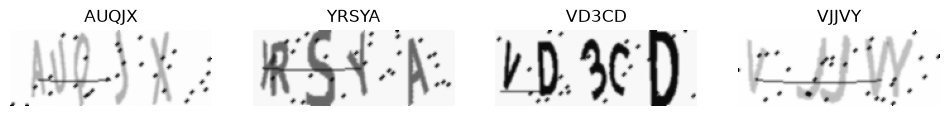

In [35]:

dataset = CaptchaDataset(10000)
loader = DataLoader(dataset, batch_size=64, num_workers=0)
xb, yb = next(iter(loader))
print(xb.shape, yb.shape)

fig, axes = plt.subplots(1, 4, figsize=(12, 2))
for i in range(4):
    axes[i].imshow(xb[i].squeeze(), cmap="gray")
    axes[i].set_title(decode(yb[i]))
    axes[i].axis("off")
plt.show()

## Step 5: Building model

In [36]:
import torch.nn as nn
import torch.nn.functional as F

class CaptchaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # ---- shared body: 3 blocks of conv → batchnorm → relu → pool ----
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)    # 1 channel in → 32 out
        self.bn1   = nn.BatchNorm2d(32)                             # rescale conv1's 32 channels

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # 32 → 64
        self.bn2   = nn.BatchNorm2d(64)                             # rescale conv2's 64 channels

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)  # 64 → 128
        self.bn3   = nn.BatchNorm2d(128)                            # rescale conv3's 128 channels

        self.pool  = nn.MaxPool2d(2)                                # halves height and width (reused)

        # ---- 5 heads: one Linear per character position ----
        self.heads = nn.ModuleList(
            [nn.Linear(128 * 7 * 20, len(CHARSET))                  # 17,920 features → 32 scores
             for _ in range(LENGTH)]                                # × 5 positions
        )

    def forward(self, x):                                           # x: (B, 1, 60, 160)
        x = self.pool(F.relu(self.bn1(self.conv1(x))))              # → (B, 32, 30, 80)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))              # → (B, 64, 15, 40)
        x = self.pool(F.relu(self.bn3(self.conv3(x))))              # → (B, 128, 7, 20)
        x = x.flatten(1)                                            # → (B, 17920)
        return [head(x) for head in self.heads]                     # → 5 × (B, 32)

In [37]:
model = CaptchaCNN()
outs = model(xb)
print(len(outs), outs[0].shape) #here xb is one batch, meaning 64 images, and the 32 means 32 characters so thinkg about scores per character for 64 images

5 torch.Size([64, 32])


## Step 6: Training

### Setup — run once
Creates a fresh, untrained model, loss function, and optimizer.
Kept separate from the training loop: re-running this cell **resets the model to zero**.

In [38]:
device = "mps"                                    # use the Mac's GPU
model = CaptchaCNN().to(device)                   # create the model and move it to the GPU
loss_fn = nn.CrossEntropyLoss()                   # measures how wrong a classification is
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)   # updates all weights (body + 5 heads)


### Training loop — run as many times as needed
Each run **continues** training the same model from where it stopped.
If the setup were in this cell too, every run would start a brand-new model from scratch.

In [39]:

for epoch in range(20):                           # 20 full passes over the data
    total_loss = 0                                # running sum of batch losses, for printing
    for xb, yb in loader:                         # one batch: 64 CAPTCHAs + their labels
        xb = xb.to(device)                        # images → GPU    (64, 1, 60, 160)
        yb = yb.to(device)                        # labels → GPU    (64, 5)
        outs = model(xb)                          # predictions: 5 × (64, 32)
        loss = sum(loss_fn(outs[i], yb[:, i])     # batch loss = sum of the 5
                   for i in range(LENGTH))        #   per-position losses
        optimizer.zero_grad()                     # clear old gradients
        loss.backward()                           # compute new gradients
        optimizer.step()                          # update the weights a little
        total_loss += loss.item()                 # add this batch's loss (as a plain number)

    print(f"Epoch {epoch}: avg loss {total_loss / len(loader):.3f}")   # average loss this epoch

Epoch 0: avg loss 20.827
Epoch 1: avg loss 11.586
Epoch 2: avg loss 6.444
Epoch 3: avg loss 4.962
Epoch 4: avg loss 4.239
Epoch 5: avg loss 3.850
Epoch 6: avg loss 3.523
Epoch 7: avg loss 3.308
Epoch 8: avg loss 3.212
Epoch 9: avg loss 2.976
Epoch 10: avg loss 2.846
Epoch 11: avg loss 2.677
Epoch 12: avg loss 2.569
Epoch 13: avg loss 2.506
Epoch 14: avg loss 2.381
Epoch 15: avg loss 2.326
Epoch 16: avg loss 2.214
Epoch 17: avg loss 2.151
Epoch 18: avg loss 2.052
Epoch 19: avg loss 2.054


In [41]:
print(xb.mean().item(), xb.std().item())

0.8725956082344055 0.15009969472885132


In [42]:
torch.save(model.state_dict(), "captcha_cnn.pt")   # save all learned weights to a file